## 1. Подготовка

### 1.1 Библиотеки и оформление

In [ ]:
import time
import logging
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("pacmap").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.manifold import TSNE, trustworthiness
from imblearn.datasets import fetch_datasets
import umap
import trimap
import pacmap

# Общее оформление графиков.(Расширение, размер текста, заголовка, фон, фон графика, цвет рамки и толщина)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfbfb",
    "axes.edgecolor": "#d9d9d9",
    "axes.linewidth": 0.8,
})

SEED = 42  # фиксируем случайность, чтобы картинки при повторном запуске не менялись
METHODS = ["t-SNE", "UMAP", "TriMap", "PaCMAP"]

# Цвета классов на графиках scene.
MAIN_COLOR = "#9aa8b5"  # класс −1, его большинство
RARE_COLOR = "#e11d48"  # класс +1, редкий


### 1.2 Функции

`embed` считает двумерные координаты.
`neighborhood_score` оценивает, насколько соседи в плоскости совпали с соседями в исходных данных, это метрика **trustworthiness**: от 0 до 1, чем больше, тем лучше.
`draw` рисует точки: для `scene` редкий класс кладётся поверх основного, для мамонта точки красятся по высоте `z`.

In [2]:
def embed(method, X, **params):
    """Считает двумерные координаты точек. Время выполнения."""
    np.random.seed(SEED)
    started = time.time()

    # Пустой params означает параметры по умолчанию.
    # fit_transform - проанализировать структуру исх. данных и сразу преобразовать их в новое двумерное представление.
    if method == "t-SNE":
        model = TSNE(n_components=2, random_state=SEED, n_jobs=-1, **params)
        Y = model.fit_transform(X)
    elif method == "UMAP":
        model = umap.UMAP(n_components=2, random_state=SEED, **params)
        Y = model.fit_transform(X)
    elif method == "TriMap":
        model = trimap.TRIMAP(n_dims=2, **params)
        Y = model.fit_transform(X)
    elif method == "PaCMAP":
        # PaCMAP ждёт непрерывный массив float32.
        model = pacmap.PaCMAP(n_components=2, random_state=SEED, **params)
        Y = model.fit_transform(np.ascontiguousarray(X, dtype=np.float32))

    return np.asarray(Y), time.time() - started


def neighborhood_score(X, Y, neighbors=12, sample=2000):
    """Trustworthiness: доля соседей в плоскости, которые были соседями и в исходных данных.

    Считается по 12 ближайшим соседям. Результат от 0 до 1, больше — лучше.
    sample=None — все точки. Иначе случайная подвыборка не больше sample:
    полная матрица расстояний на мамонте из 10 000 точек слишком тяжёлая.
    """
    n = len(X) if sample is None else min(sample, len(X))
    if n == len(X):
        return trustworthiness(np.asarray(X), Y, n_neighbors=neighbors)
    taken = np.random.RandomState(SEED).choice(len(X), size=n, replace=False)
    return trustworthiness(np.asarray(X)[taken], Y[taken], n_neighbors=neighbors)


def draw(ax, Y, color, classes=False, equal=False):
    """Рисует вложение. classes=True — два класса scene, иначе цвет задаёт число (высота z)."""
    if classes:
        rare = color == 1
        # Сначала основной класс, потом редкий поверх него, иначе редкие точки теряются.
        ax.scatter(*Y[~rare].T, s=8, c=MAIN_COLOR, alpha=0.55, linewidths=0, rasterized=True)
        ax.scatter(*Y[rare].T, s=18, c=RARE_COLOR, alpha=0.9, linewidths=0, rasterized=True)
    else:
        ax.scatter(*Y.T, s=3, c=color, cmap="turbo", alpha=0.75, linewidths=0, rasterized=True)
    if equal:
        # Для мамонта одинаковый масштаб по осям, иначе силуэт растягивается.
        ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])


### 1.3 Функции перебора параметров и перебора масштабирования


In [3]:
def try_params(method, settings, X, color, classes=False, equal=False, title="", score_sample=2000):
    """Прогоняет один алгоритм по списку настроек и рисует сетку 2×4.

    settings — список пар (подпись на графике, словарь параметров).
    Последняя панель пустая: туда ставится легенда.
    """
    #создаётсетку 2 строкu и 4 столбцa подграфиков и общий размер всей фигуры — 15,5 дюймов в ширину и 8 в высоту. 
    figure, axes = plt.subplots(2, 4, figsize=(15.5, 8))
    rows = []
    
    # Перебор настроек-> координаты и время-> метрика оценки качества-> рисунок-> заголовки-> данные в список 
    for ax, (label, params) in zip(axes.ravel(), settings):
        Y, seconds = embed(method, X, **params)
        quality = neighborhood_score(X, Y, sample=score_sample)
        draw(ax, Y, color, classes=classes, equal=equal)
        ax.set_title(f"{label}\ntrustworthiness {quality:.3f}   ·   {seconds:.0f} с")
        rows.append({
            "Параметры": label,
            "trustworthiness": round(quality, 4),
            "Время, с": round(seconds, 1),
        })
        print(f"{method:<7} | {label:<28} | trustworthiness {quality:.4f} | {seconds:5.1f} с")

    # Ячеек в сетке 8,а настроек 7, лишнюю ячейку в сетке графиков занимаем легендой.
    note = axes.ravel()[-1]
    note.axis("off")
    if classes:
        note.legend(
            handles=[
                Line2D([], [], marker="o", linestyle="", markersize=8, color=MAIN_COLOR, label="класс −1"),
                Line2D([], [], marker="o", linestyle="", markersize=8, color=RARE_COLOR, label="класс +1, редкий"),
            ],
            loc="center", frameon=False, fontsize=11, title="цвет точки",
        )
    else:
        note.text(0.5, 0.5, "цвет точки — высота z\nсиний низ, красный верх",
                  ha="center", va="center", fontsize=11, color="#444444")

    figure.suptitle(title, fontsize=14, fontweight="bold")
    figure.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index("Параметры")


def prepare(X):
    """Четыре копии данных: как есть и после трёх способов масштабирования."""
    return {
        "без масштабирования": np.asarray(X, float),
        "MinMax": MinMaxScaler().fit_transform(X),      # каждый признак в отрезок [0, 1]
        "Standard": StandardScaler().fit_transform(X),  # среднее 0, стандартное отклонение 1
        "Robust": RobustScaler().fit_transform(X),      # медиана 0, деление на межквартильный размах
    }

# сводка табличная со знач
def scaling_report(variants):
    """Сводка по признакам: min, max, std и IQR, усреднённые по всем столбцам."""
    rows = {}
    for name, data in variants.items():
        low, high = np.percentile(data, [25, 75], axis=0)
        rows[name] = {
            "средний min": data.min(0).mean(),
            "средний max": data.max(0).mean(),
            "средний std": data.std(0).mean(),#среднее по стандартным отклонениям: общая изменчивость/разброс данных.
            "средний IQR": (high - low).mean(),#средний межквартильный размах: устойчивая к выбросам мера разброса.
        }
    return pd.DataFrame(rows).T.round(3)

# отрисовка графиков сравнения масштабирования
def try_scaling(variants, color, classes=False, equal=False, title="", score_sample=2000):
    """Матрица визуализаций: по строкам — алгоритмы снижения размерности, по столбецам — способы масштабирования.
    Все алгоритмы здесь запускаются с параметрами по умолчанию.
    """
    names = list(variants)
    figure, axes = plt.subplots(len(METHODS), len(names), figsize=(14, 13))
    rows = []

    for row, method in enumerate(METHODS):
        for col, name in enumerate(names):
            Y, seconds = embed(method, variants[name])
            quality = neighborhood_score(variants[name], Y, sample=score_sample)
            ax = axes[row, col]
            draw(ax, Y, color, classes=classes, equal=equal)
            ax.set_title(f"{quality:.3f}   ·   {seconds:.0f} с", fontsize=9)
            if row == 0:
                ax.set_title(f"{name}\n{quality:.3f}   ·   {seconds:.0f} с", fontsize=10)
            if col == 0:
                ax.set_ylabel(method, fontsize=11, fontweight="bold")
            rows.append({
                "Алгоритм": method,
                "Масштабирование": name,
                "trustworthiness": round(quality, 4),
            })
            print(f"{method:<7} | {name:<22} | trustworthiness {quality:.4f} | {seconds:5.1f} с")

    figure.suptitle(title, fontsize=14, fontweight="bold")
    figure.tight_layout()
    plt.show()
    #превращаем список в таблицу
    table = pd.DataFrame(rows).pivot(
        index="Алгоритм", columns="Масштабирование", values="trustworthiness"
    )
    return table.loc[METHODS, names]


In [5]:
# Задаю набор параметров для каждого алгоритма

# Еarly_exaggeration — насколько сильно разводить группы в начале, learning_rate — шаг оптимизации, perplexity — сколько соседей учитывать.
TSNE_SETTINGS = [
    ("по умолчанию", {}),
    ("perplexity = 5", {"perplexity": 5}),
    ("perplexity = 50", {"perplexity": 50}),
    ("perplexity = 100", {"perplexity": 100}),
    ("learning_rate = 10", {"learning_rate": 10}),
    ("early_exaggeration = 4", {"early_exaggeration": 4, "init": "random"}),
    ("метрика manhattan", {"metric": "manhattan", "init": "random"}),
]

# min_dist — насколько плотно сжимать точки на рисунке,spread — общий масштаб распределения точек, n_neighbors — размер окрестности.
UMAP_SETTINGS = [
    ("по умолчанию", {}),
    ("5 соседей, min_dist = 0", {"n_neighbors": 5, "min_dist": 0.0}),
    ("50 соседей", {"n_neighbors": 50}),
    ("200 соседей, min_dist = 0.5", {"n_neighbors": 200, "min_dist": 0.5}),
    ("min_dist = 0.9", {"min_dist": 0.9}),
    ("30 соседей, spread = 3", {"n_neighbors": 30, "spread": 3.0}),
    ("метрика manhattan", {"metric": "manhattan"}),
]

# n_inliers — близкие точки триплета, n_outliers — далёкие (чем больше далёких, тем сильнее сохраняется общая форма облака).
TRIMAP_SETTINGS = [
    ("по умолчанию", {}),
    ("5 близких, 2 далёких", {"n_inliers": 5, "n_outliers": 2}),
    ("30 близких, 10 далёких", {"n_inliers": 30, "n_outliers": 10}),
    ("50 близких, 20 далёких", {"n_inliers": 50, "n_outliers": 20}),
    ("weight_temp = 0", {"weight_temp": 0.0}),
    ("1000 итераций", {"n_iters": 1000, "lr": 0.05}),
    ("метрика manhattan", {"distance": "manhattan"}),
]

# MN_ratio — пары среднего радиуса (держат общую структуру), FP_ratio — дальние пары (расталкивают точки, чтобы они не слиплись).
PACMAP_SETTINGS = [
    ("по умолчанию", {}),
    ("5 соседей", {"n_neighbors": 5}),
    ("30 соседей", {"n_neighbors": 30}),
    ("MN_ratio = 0.1", {"MN_ratio": 0.1}),
    ("MN_ratio = 2", {"MN_ratio": 2.0}),
    ("FP_ratio = 5", {"FP_ratio": 5.0}),
    ("метрика manhattan", {"distance": "manhattan"}),
]

SETTINGS = {
    "t-SNE": TSNE_SETTINGS,
    "UMAP": UMAP_SETTINGS,
    "TriMap": TRIMAP_SETTINGS,
    "PaCMAP": PACMAP_SETTINGS,
}


### Задание 1. Набор `scene`

In [6]:
#загрузила набор
# fetch_datasets отдаёт объект с матрицей признаков .data и меткой .target.
loaded = fetch_datasets(filter_data=("scene",))["scene"]
X_scene = np.asarray(loaded.data, dtype=float)
y_scene = np.asarray(loaded.target, dtype=int)

labels, counts = np.unique(y_scene, return_counts=True)
print(f"Размер: {X_scene.shape[0]} примеров, {X_scene.shape[1]} признаков")
print(f"Класс −1: {counts[0]}")
print(f"Класс +1: {counts[1]}")
print(f"Баланс: {counts[0] / counts[1]:.1f} : 1")

Размер: 2407 примеров, 294 признаков
Класс −1: 2230
Класс +1: 177
Баланс: 12.6 : 1


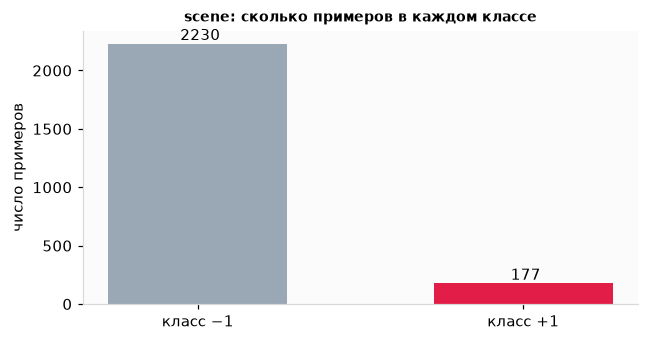

In [7]:
#нарисов. график визуализацию
#Высота столбца — число примеров. Редкий класс рядом с основным почти не виден: баланс около 13:1.
figure, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(["класс −1", "класс +1"], counts, color=[MAIN_COLOR, RARE_COLOR], width=0.55)
for position, count in enumerate(counts):
    ax.text(position, count, f" {count}", ha="center", va="bottom")
ax.set_title("scene: сколько примеров в каждом классе", fontweight="bold")
ax.set_ylabel("число примеров")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
figure.tight_layout()
plt.show()


### 2.1 Масштабирование

Признаков 294, и их разброс сильно отличается. 
Без масштабирования расстояние между точками задают только самые «широкие» признаки.
MinMax растягивает/сжимает значения признака чтобы минимум стал 0, максимум стал 1. Standard уравнивает по среднему (мат ожид) 0 и стандартному отклонению 1; сохраняет форму распределения, Robust центрирует по медиане и масштабирует по межквартильному размаху (IQR) и поэтому меньше реагирует на выбросы.


In [8]:
scene = prepare(X_scene)#масштабирование
display(scaling_report(scene))


,средний min,средний max,средний std,средний IQR
без масштабирования,0.000,1.000,0.181,0.190
MinMax,0.000,1.000,0.181,0.190
Standard,-1.605,4.404,1.000,0.983
Robust,-1.237,7.511,1.233,1.000


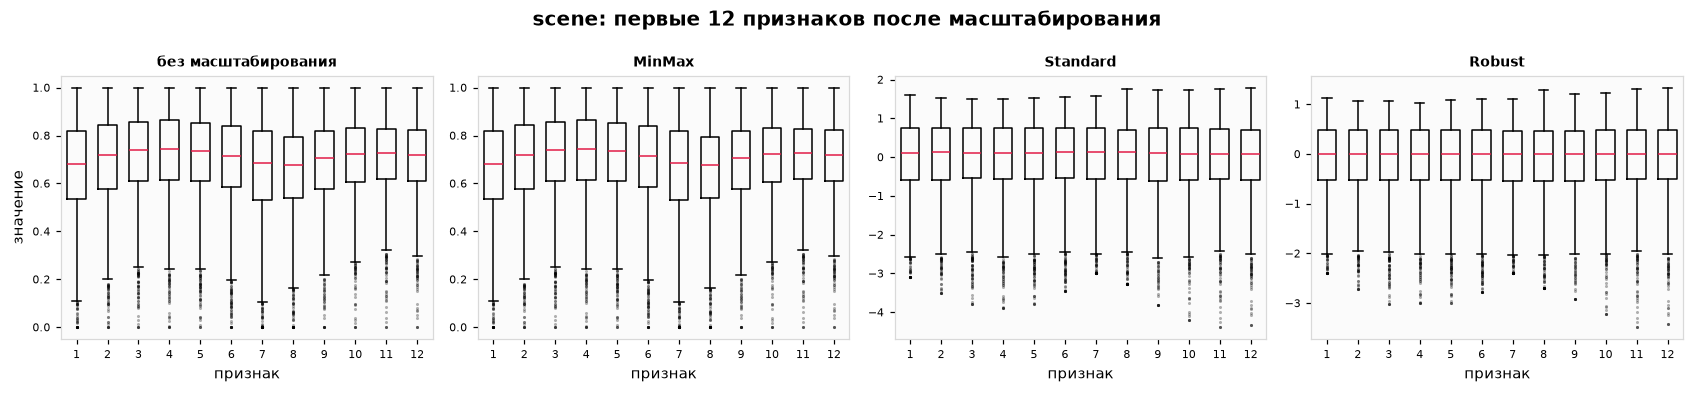

In [9]:
#Рисуем график распределения первых 12 признаков после применения масштабирования (так видно, выровнялись ли масштабы столбцов.)
figure, axes = plt.subplots(1, 4, figsize=(15.5, 3.6))
for ax, (name, data) in zip(axes, scene.items()):
    ax.boxplot(
        data[:, :12],
        widths=0.6, 
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.3},
        medianprops={"color": RARE_COLOR},
    )
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("признак")
    ax.tick_params(labelsize=7)
axes[0].set_ylabel("значение")
figure.suptitle("scene: первые 12 признаков после масштабирования", fontsize=13, fontweight="bold")
figure.tight_layout()
plt.show()


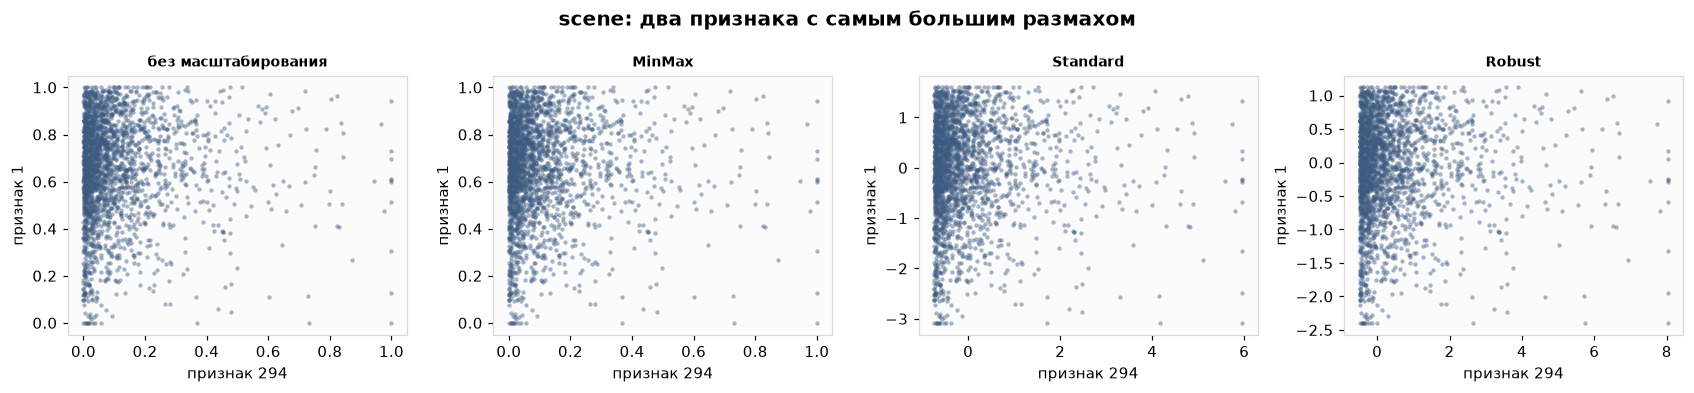

In [10]:
# Берем два самых больших признака по разбросу значений и показываем как разброс смасштабировался 
wide = np.argsort(X_scene.max(0) - X_scene.min(0))[-2:]
figure, axes = plt.subplots(1, 4, figsize=(15.5, 3.6))
for ax, (name, data) in zip(axes, scene.items()):
    ax.scatter(data[:, wide[0]], data[:, wide[1]], s=8, c="#3d5a80", alpha=0.45, linewidths=0)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel(f"признак {wide[0] + 1}")
    ax.set_ylabel(f"признак {wide[1] + 1}")
figure.suptitle("scene: два признака с самым большим размахом", fontsize=13, fontweight="bold")
figure.tight_layout()
plt.show()
# Выбрали Standard как функцию масштабирования для послед. работы алгоритмов
X_scene_std = scene["Standard"]


### 2.2 t-SNE

t-SNE сближает в плоскости те точки, которые были соседями в исходных данных.
`perplexity` задаёт, сколько соседей при этом учитывается.

t-SNE   | по умолчанию                 | trustworthiness 0.8599 |   9.2 с
t-SNE   | perplexity = 5               | trustworthiness 0.8508 |   7.7 с
t-SNE   | perplexity = 50              | trustworthiness 0.8607 |  12.5 с
t-SNE   | perplexity = 100             | trustworthiness 0.8545 |  13.8 с
t-SNE   | learning_rate = 10           | trustworthiness 0.8610 |   9.2 с
t-SNE   | early_exaggeration = 4       | trustworthiness 0.8639 |   9.9 с
t-SNE   | метрика manhattan            | trustworthiness 0.8496 |  10.3 с


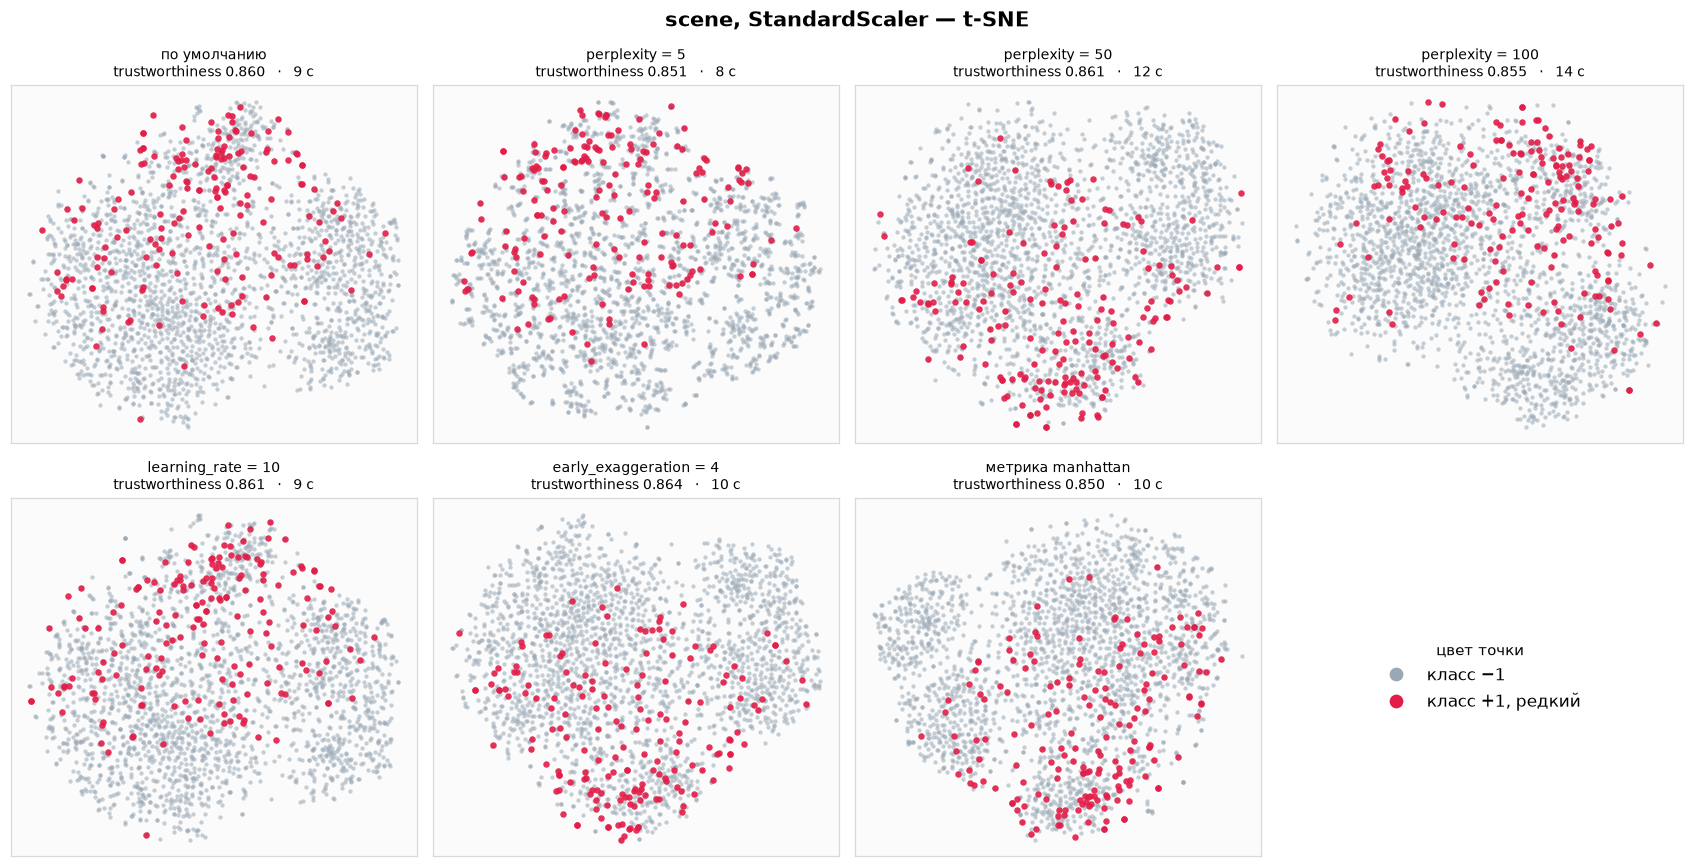

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.8599,9.2
perplexity = 5,0.8508,7.7
perplexity = 50,0.8607,12.5
perplexity = 100,0.8545,13.8
learning_rate = 10,0.8610,9.2
early_exaggeration = 4,0.8639,9.9
метрика manhattan,0.8496,10.3


In [11]:

scene_tsne = try_params(
    "t-SNE", TSNE_SETTINGS, X_scene_std, y_scene, classes=True,# classes=True красит редкий класс красным. Данные уже после StandardScaler.
    score_sample=None,
    title="scene, StandardScaler — t-SNE",
)
display(scene_tsne)


### 2.3 UMAP

`n_neighbors` использует окресность. Маленькое `min_dist` собирает точки в плотные группы, большое — раздвигает их.

UMAP    | по умолчанию                 | trustworthiness 0.8111 |  28.2 с
UMAP    | 5 соседей, min_dist = 0      | trustworthiness 0.8310 |   9.8 с
UMAP    | 50 соседей                   | trustworthiness 0.7962 |  15.3 с
UMAP    | 200 соседей, min_dist = 0.5  | trustworthiness 0.7662 |  20.0 с
UMAP    | min_dist = 0.9               | trustworthiness 0.7643 |  13.3 с
UMAP    | 30 соседей, spread = 3       | trustworthiness 0.8133 |  15.2 с
UMAP    | метрика manhattan            | trustworthiness 0.7965 |  13.3 с


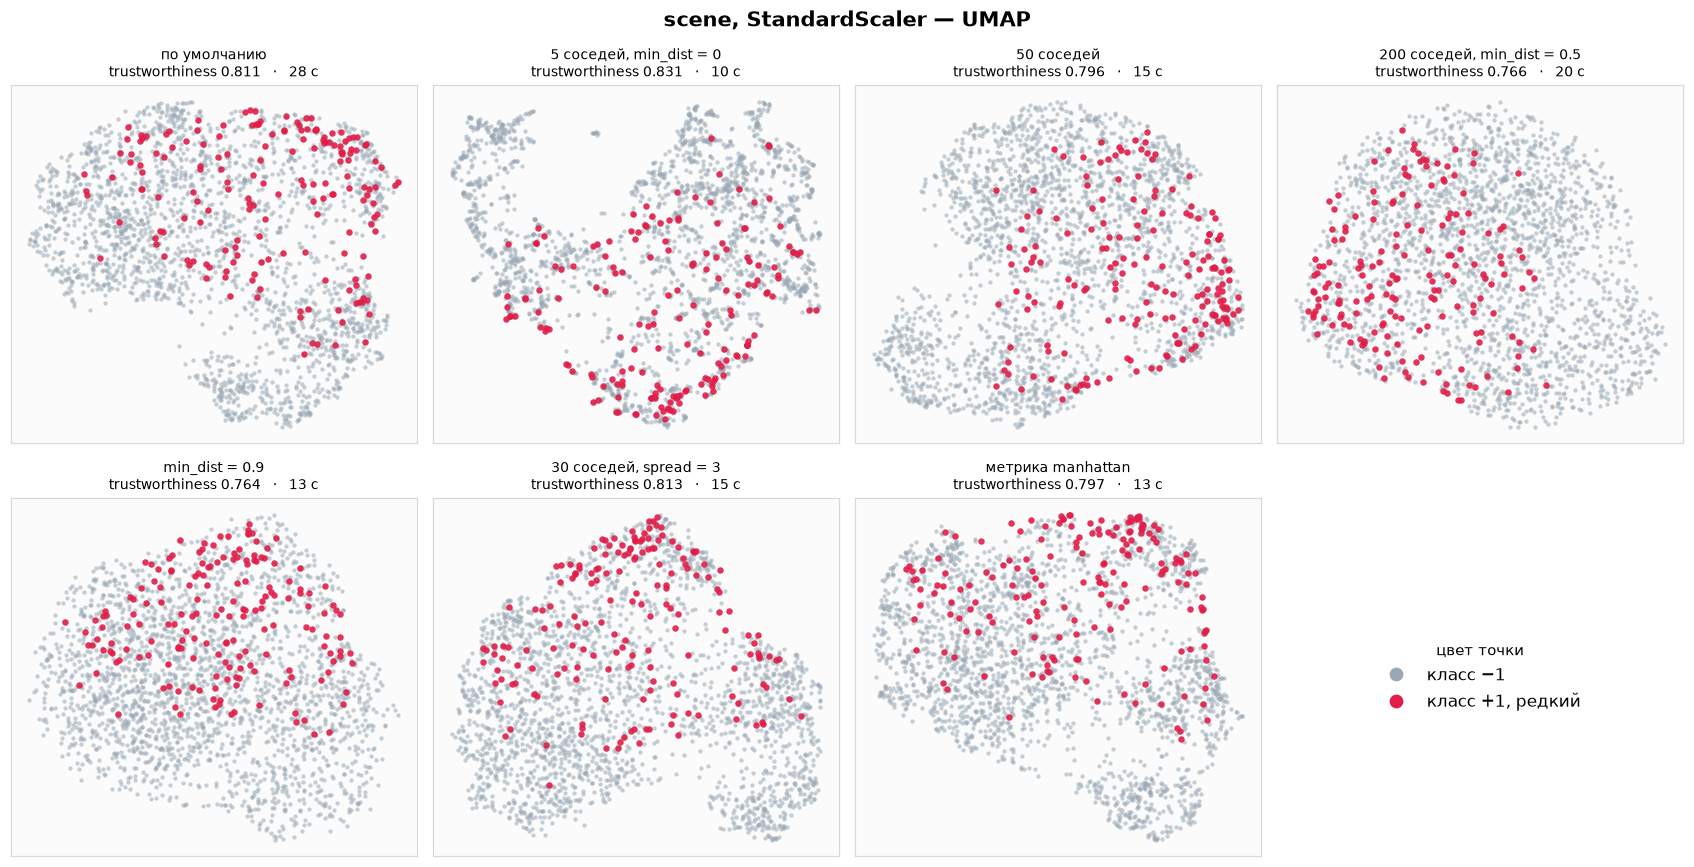

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.8111,28.2
"5 соседей, min_dist = 0",0.8310,9.8
50 соседей,0.7962,15.3
"200 соседей, min_dist = 0.5",0.7662,20.0
min_dist = 0.9,0.7643,13.3
"30 соседей, spread = 3",0.8133,15.2
метрика manhattan,0.7965,13.3


In [12]:
scene_umap = try_params(
    "UMAP", UMAP_SETTINGS, X_scene_std, y_scene, classes=True,
    score_sample=None,
    title="scene, StandardScaler — UMAP",
)
display(scene_umap)


### 2.4 TriMap

TriMap сравнивает тройки точек: «эта точка ближе к первой, чем ко второй».
Чем больше далёких точек (`n_outliers`), тем сильнее алгоритм держит общую форму облака, а не только мелкие группы.

TriMap  | по умолчанию                 | trustworthiness 0.8206 |  14.0 с
TriMap  | 5 близких, 2 далёких         | trustworthiness 0.7924 |   1.0 с
TriMap  | 30 близких, 10 далёких       | trustworthiness 0.8346 |   9.8 с
TriMap  | 50 близких, 20 далёких       | trustworthiness 0.8322 |  41.9 с
TriMap  | weight_temp = 0              | trustworthiness 0.8180 |   3.0 с
TriMap  | 1000 итераций                | trustworthiness 0.8231 |   5.7 с
TriMap  | метрика manhattan            | trustworthiness 0.8177 |   3.4 с


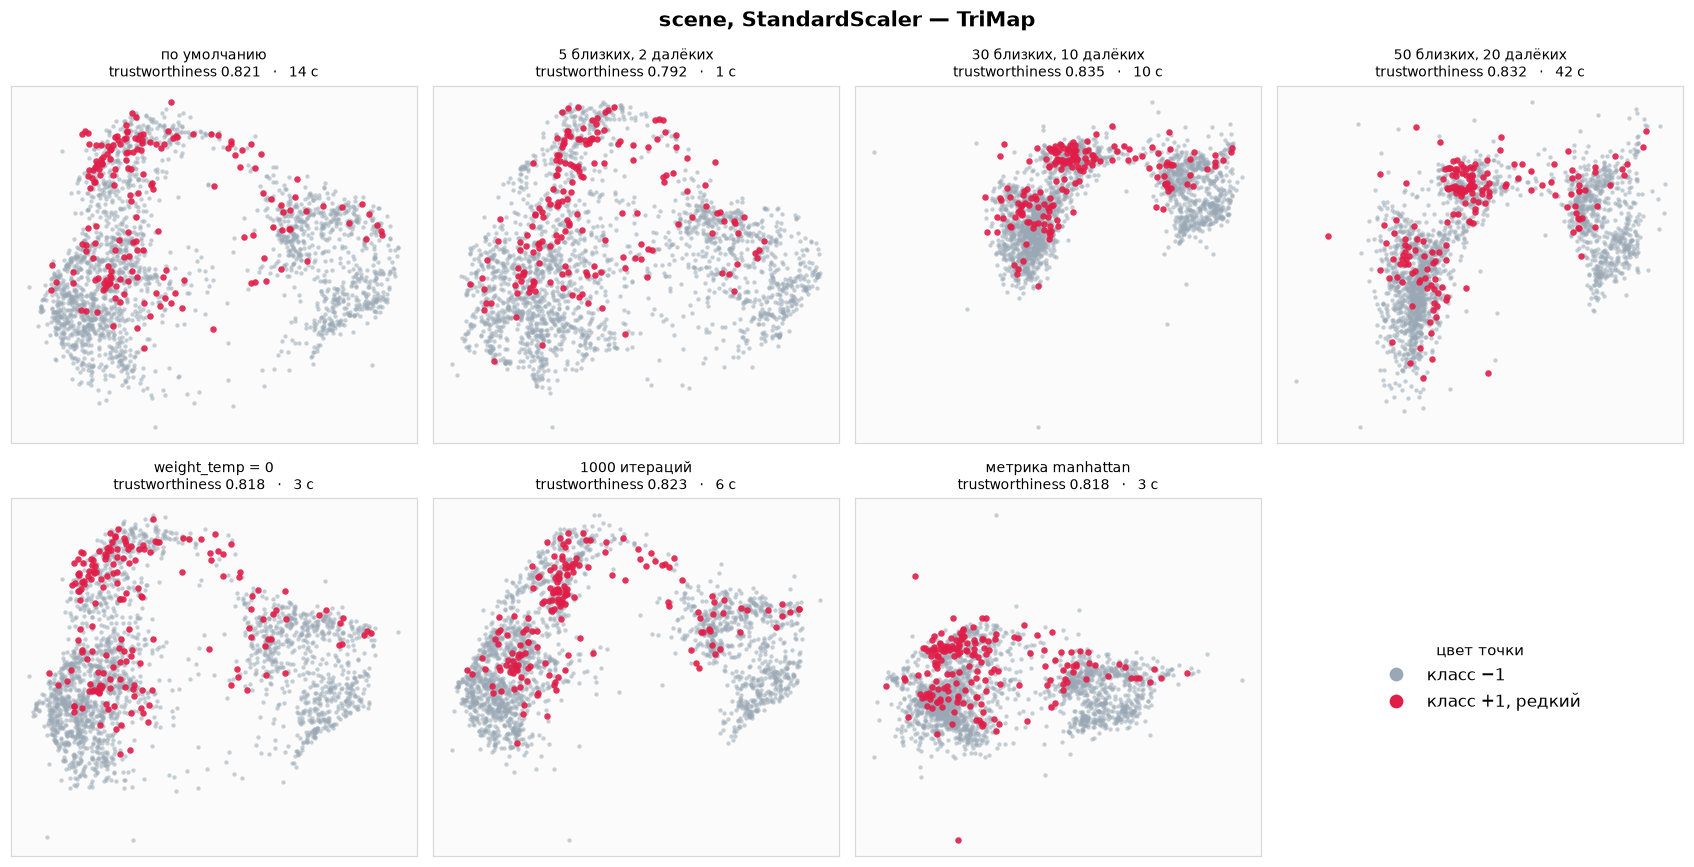

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.8206,14.0
"5 близких, 2 далёких",0.7924,1.0
"30 близких, 10 далёких",0.8346,9.8
"50 близких, 20 далёких",0.8322,41.9
weight_temp = 0,0.8180,3.0
1000 итераций,0.8231,5.7
метрика manhattan,0.8177,3.4


In [13]:
scene_trimap = try_params(
    "TriMap", TRIMAP_SETTINGS, X_scene_std, y_scene, classes=True,
    score_sample=None,  # scene целиком, без подвыборки в 2000 точек
    title="scene, StandardScaler — TriMap",
)
display(scene_trimap)


### 2.5 PaCMAP

PaCMAP одновременно притягивает соседей, удерживает пары среднего расстояния (`MN_ratio`) и отталкивает дальние пары (`FP_ratio`).

PaCMAP  | по умолчанию                 | trustworthiness 0.8175 |   1.6 с
PaCMAP  | 5 соседей                    | trustworthiness 0.8060 |   0.8 с
PaCMAP  | 30 соседей                   | trustworthiness 0.8139 |   3.9 с
PaCMAP  | MN_ratio = 0.1               | trustworthiness 0.8178 |   1.4 с
PaCMAP  | MN_ratio = 2                 | trustworthiness 0.8165 |   2.3 с
PaCMAP  | FP_ratio = 5                 | trustworthiness 0.8590 |   2.3 с
PaCMAP  | метрика manhattan            | trustworthiness 0.7884 |   1.7 с


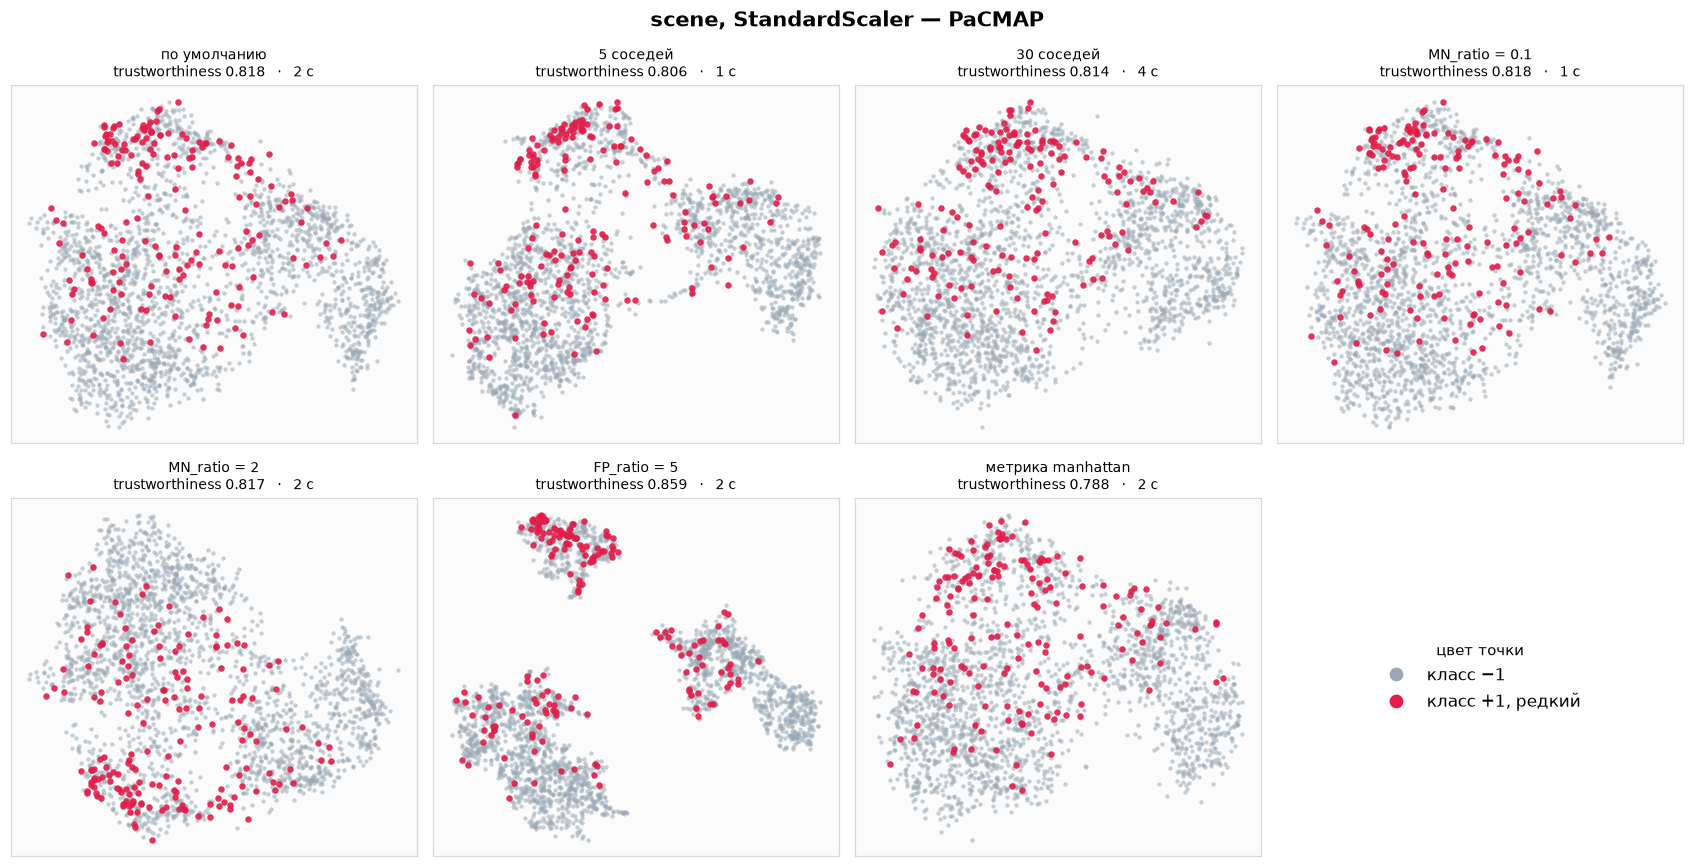

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.8175,1.6
5 соседей,0.8060,0.8
30 соседей,0.8139,3.9
MN_ratio = 0.1,0.8178,1.4
MN_ratio = 2,0.8165,2.3
FP_ratio = 5,0.8590,2.3
метрика manhattan,0.7884,1.7


In [14]:
scene_pacmap = try_params(
    "PaCMAP", PACMAP_SETTINGS, X_scene_std, y_scene, classes=True,
    score_sample=None,  # scene целиком, без подвыборки в 2000 точек
    title="scene, StandardScaler — PaCMAP",
)
display(scene_pacmap)


### 2.6 Одни и те же алгоритмы на разных масштабах



t-SNE   | без масштабирования    | trustworthiness 0.8876 |  15.9 с
t-SNE   | MinMax                 | trustworthiness 0.8842 |  14.6 с
t-SNE   | Standard               | trustworthiness 0.8574 |  16.8 с
t-SNE   | Robust                 | trustworthiness 0.8149 |  16.9 с
UMAP    | без масштабирования    | trustworthiness 0.8363 |  11.9 с
UMAP    | MinMax                 | trustworthiness 0.8321 |  12.3 с
UMAP    | Standard               | trustworthiness 0.8111 |  12.0 с
UMAP    | Robust                 | trustworthiness 0.7699 |  11.5 с
TriMap  | без масштабирования    | trustworthiness 0.8544 |   2.1 с
TriMap  | MinMax                 | trustworthiness 0.8556 |   2.1 с
TriMap  | Standard               | trustworthiness 0.8186 |   2.1 с
TriMap  | Robust                 | trustworthiness 0.7644 |   2.2 с
PaCMAP  | без масштабирования    | trustworthiness 0.8492 |   1.1 с
PaCMAP  | MinMax                 | trustworthiness 0.8487 |   1.1 с
PaCMAP  | Standard               | trustworthine

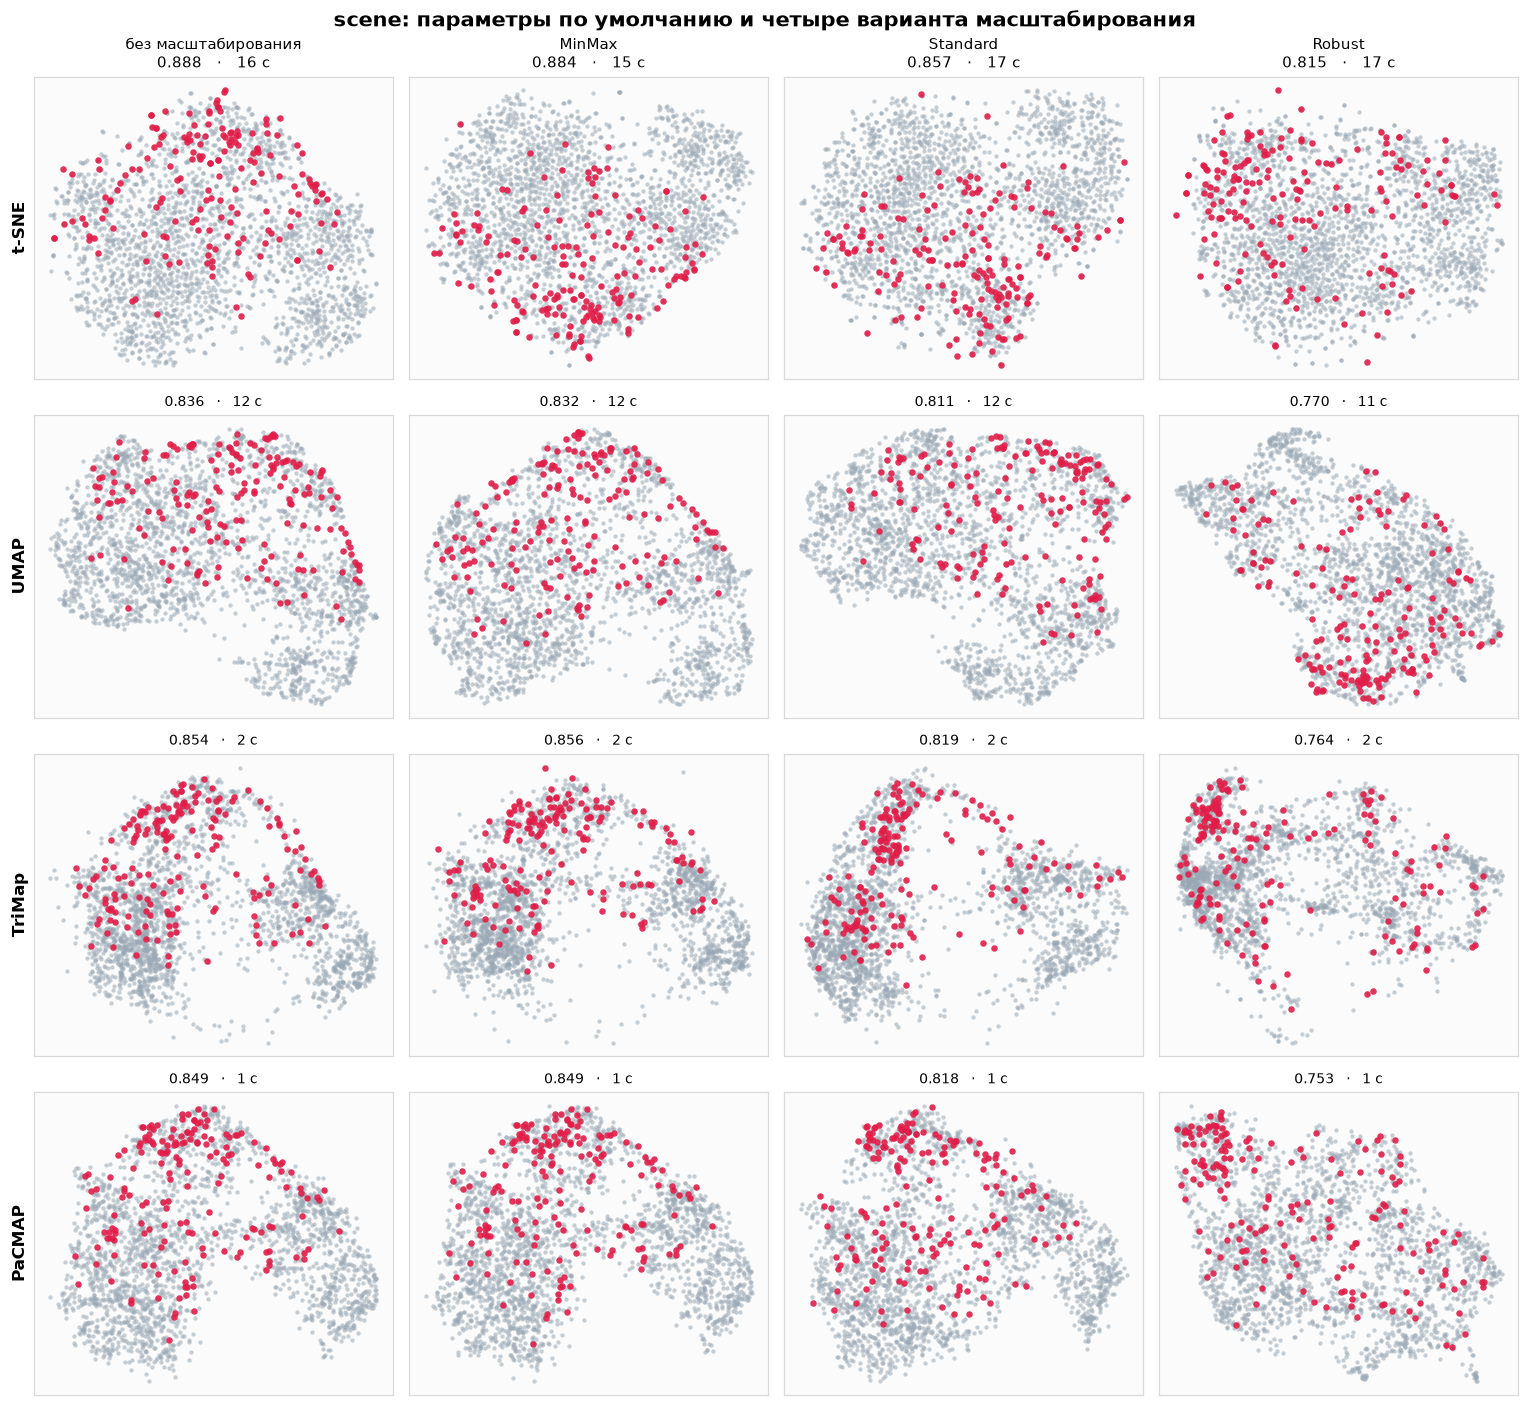

trustworthiness


Масштабирование,без масштабирования,MinMax,Standard,Robust
Алгоритм,,,,
t-SNE,0.8876,0.8842,0.8574,0.8149
UMAP,0.8363,0.8321,0.8111,0.7699
TriMap,0.8544,0.8556,0.8186,0.7644
PaCMAP,0.8492,0.8487,0.8175,0.7526


In [15]:
# Здесь параметры у всех алгоритмов по умолчанию, меняется только масштабирование.
scene_scaling = try_scaling(
    scene, y_scene, classes=True,
    score_sample=None,
    title="scene: параметры по умолчанию и четыре варианта масштабирования",
)
print("trustworthiness")
display(scene_scaling)


### 2.7 Сравнение алгоритмов на `scene`

In [16]:
# Склеиваем четыре таблицы в одну, чтобы сравнить алгоритмы между собой.
scene_results = []
for method, result in [("t-SNE", scene_tsne), ("UMAP", scene_umap),
                       ("TriMap", scene_trimap), ("PaCMAP", scene_pacmap)]:
    part = result.reset_index()
    part.insert(0, "Алгоритм", method)
    scene_results.append(part)
scene_results = pd.concat(scene_results, ignore_index=True)

print("Среднее и лучшее значение по 7 настройкам")
display(
    scene_results.groupby("Алгоритм")[["trustworthiness", "Время, с"]]
    .agg(["mean", "max"])
    .round(4)
    .loc[METHODS]
)

# idxmax даёт номер строки с наибольшим trustworthiness внутри каждого алгоритма.
best_rows = scene_results.groupby("Алгоритм")["trustworthiness"].idxmax()
print("Лучшая настройка каждого алгоритма")
display(scene_results.loc[best_rows].set_index("Алгоритм").loc[METHODS])


Среднее и лучшее значение по 7 настройкам


trustworthiness         Время, с      
                    mean     max     mean   max
Алгоритм                                       
t-SNE             0.8572  0.8639  10.3714  13.8
UMAP              0.7969  0.8310  16.4429  28.2
TriMap            0.8198  0.8346  11.2571  41.9
PaCMAP            0.8170  0.8590   2.0000   3.9

Лучшая настройка каждого алгоритма


,Параметры,trustworthiness,"Время, с"
Алгоритм,,,
t-SNE,early_exaggeration = 4,0.8639,9.9
UMAP,"5 соседей, min_dist = 0",0.8310,9.8
TriMap,"30 близких, 10 далёких",0.8346,9.8
PaCMAP,FP_ratio = 5,0.8590,2.3


## 3. Задание 2. Трёхмерный мамонт в плоскости

Файл `mammoth (1).csv` — скелет мамонта из точек `x`, `y`, `z`.
Форма объекта заранее известна, поэтому на рисунке сразу видно, порвал алгоритм ноги с корпусом или сохранил силуэт.

Берётся 10 000 случайных точек. Цвет — высота `z`: синий у ступней, красный у спины и головы.

In [20]:
mammoth_table = pd.read_csv("mammoth (1).csv")
print(f"В файле {len(mammoth_table)} точек, столбцы: {list(mammoth_table.columns)}")

# 10 000 случайных точек. Полный файл почти на миллион строк, полный прогон был бы слишком долгим.
X_mammoth = mammoth_table.sample(n=10_000, random_state=SEED).to_numpy(float)
height = X_mammoth[:, 2]  # по этой координате красим точки: это высота скелета
print(f"В работу взято {len(X_mammoth)} случайных точек")
display(mammoth_table.describe().round(2))


В файле 999778 точек, столбцы: ['x', 'y', 'z']
В работу взято 10000 случайных точек


,x,y,z
count,999778.00,999778.00,999778.00
mean,76.64,353.81,45.88
std,33.86,105.52,89.85
min,-22.53,60.95,-172.22
25%,50.90,289.24,15.19
50%,76.65,335.66,80.70
75%,102.44,435.57,112.86
max,169.60,568.92,172.24


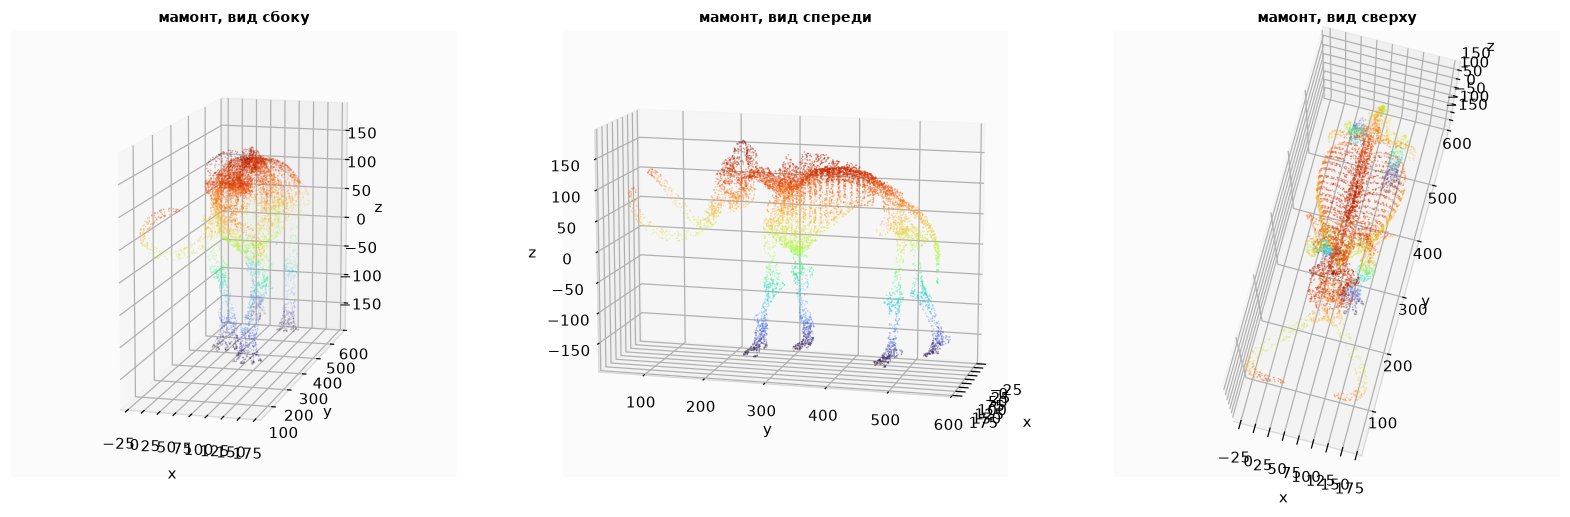

In [21]:
# Три ракурса одного и того же облака. elev и azim — угол камеры.
figure = plt.figure(figsize=(15, 4.6))
views = [(12, -75, "сбоку"), (12, 15, "спереди"), (78, -75, "сверху")]
for number, (elev, azim, name) in enumerate(views, start=1):
    ax = figure.add_subplot(1, 3, number, projection="3d")
    ax.scatter(*X_mammoth.T, s=1, c=height, cmap="turbo", alpha=0.7, linewidths=0, rasterized=True)
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect(np.ptp(X_mammoth, axis=0))  # пропорции осей как у реальных размахов x, y, z
    ax.set_title(f"мамонт, вид {name}", fontweight="bold")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
figure.tight_layout()
plt.show()


### 3.1 Масштабирование

Три координаты измерены в одних единицах, но размах по `y` больше, чем по `x` и `z`.

In [35]:
mammoth = prepare(X_mammoth)
display(scaling_report(mammoth))


,средний min,средний max,средний std,средний IQR
без масштабирования,-44.303,303.500,76.612,98.428
MinMax,0.000,1.000,0.216,0.280
Standard,-2.691,2.068,1.000,1.327
Robust,-2.117,1.455,0.767,1.000


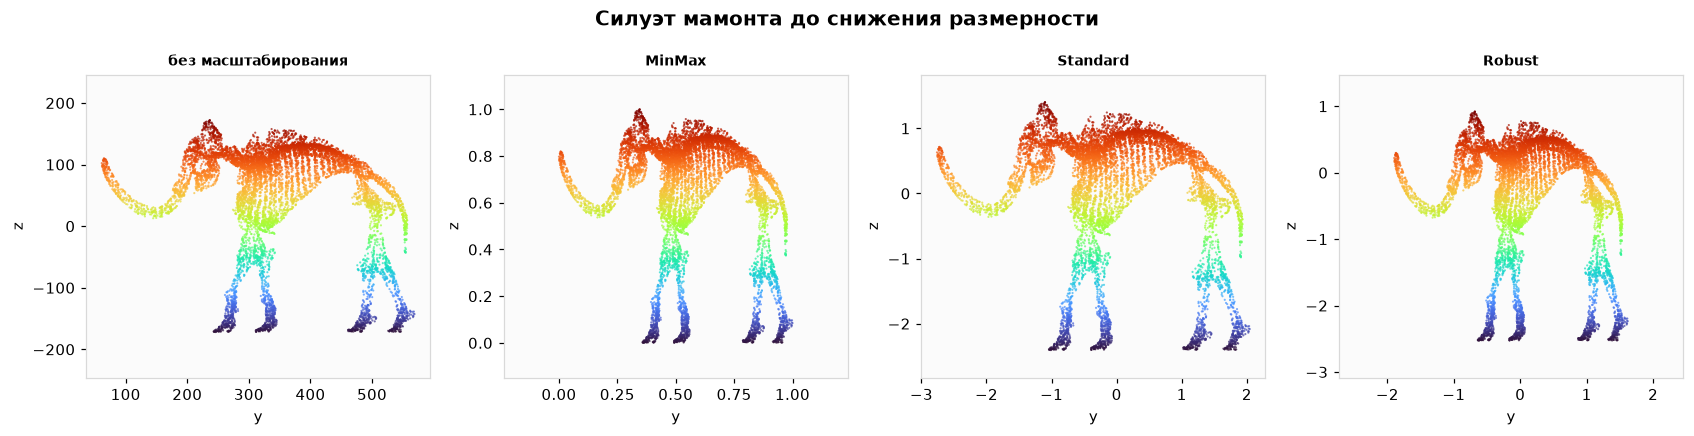

In [36]:
# отрисуем проекцию y–z, чтобы показать что масштабирование меняет пропорции скелета ещё до алгоритма.
figure, axes = plt.subplots(1, 4, figsize=(15.5, 4))
for ax, (name, data) in zip(axes, mammoth.items()):
    ax.scatter(data[:, 1], data[:, 2], s=2, c=height, cmap="turbo", alpha=0.7, linewidths=0, rasterized=True)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("y")
    ax.set_ylabel("z")
figure.suptitle("Силуэт мамонта до снижения размерности", fontsize=13, fontweight="bold")
figure.tight_layout()
plt.show()

X_mammoth_std = mammoth["Standard"]


### 3.2 t-SNE

Маленькая `perplexity` режет скелет на куски. Большая старается удержать его целиком.

In [ ]:
# equal=True сохраняет пропорции, color=height красит точки по высоте.
mammoth_tsne = try_params(
    "t-SNE", TSNE_SETTINGS, X_mammoth_std, height, equal=True,
    title="мамонт, StandardScaler — t-SNE",
)
display(mammoth_tsne)


### 3.3 UMAP

Мало соседей разворачивает хобот, ноги и рёбра по отдельности. Много соседей держит общий контур.

UMAP    | по умолчанию                 | trustworthiness 0.9982 | 103.4 с
UMAP    | 5 соседей, min_dist = 0      | trustworthiness 0.9221 |  34.6 с
UMAP    | 50 соседей                   | trustworthiness 0.9983 |  66.0 с
UMAP    | 200 соседей, min_dist = 0.5  | trustworthiness 0.9984 | 119.0 с
UMAP    | min_dist = 0.9               | trustworthiness 0.9934 |  42.8 с
UMAP    | 30 соседей, spread = 3       | trustworthiness 0.9980 |  54.9 с
UMAP    | метрика manhattan            | trustworthiness 0.9981 |  66.6 с


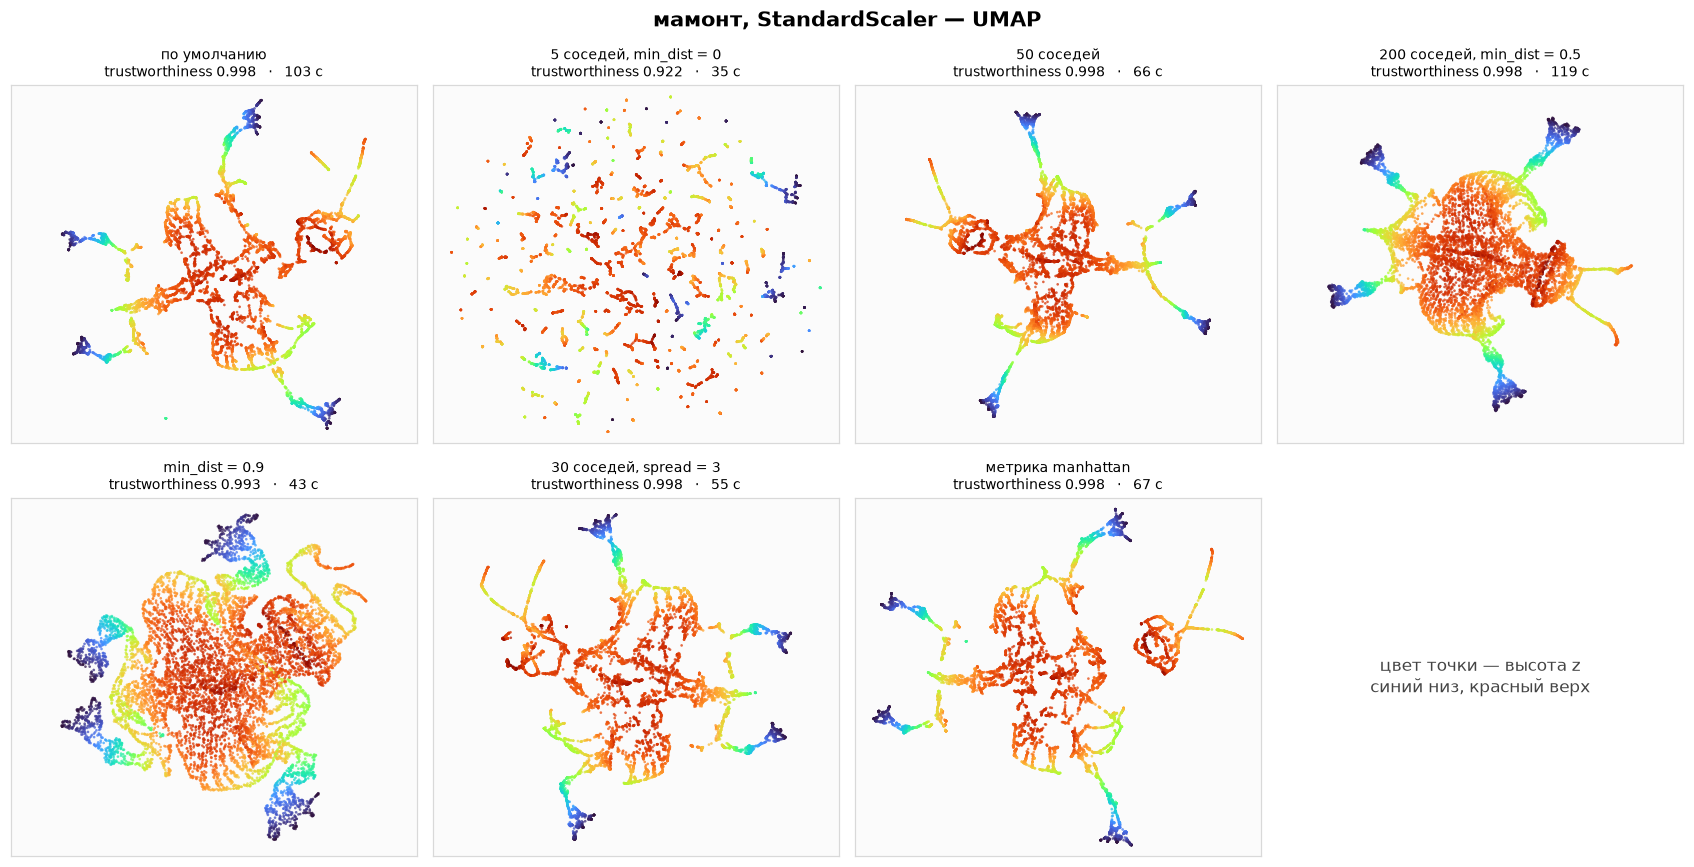

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.9982,103.4
"5 соседей, min_dist = 0",0.9221,34.6
50 соседей,0.9983,66.0
"200 соседей, min_dist = 0.5",0.9984,119.0
min_dist = 0.9,0.9934,42.8
"30 соседей, spread = 3",0.9980,54.9
метрика manhattan,0.9981,66.6


In [25]:
mammoth_umap = try_params(
    "UMAP", UMAP_SETTINGS, X_mammoth_std, height, equal=True,
    title="мамонт, StandardScaler — UMAP",
)
display(mammoth_umap)


### 3.4 TriMap

Триплеты с далёкими точками удерживают взаимное расположение частей тела, поэтому силуэт обычно остаётся узнаваемым.

TriMap  | по умолчанию                 | trustworthiness 0.9820 |  27.9 с
TriMap  | 5 близких, 2 далёких         | trustworthiness 0.9804 |  11.1 с
TriMap  | 30 близких, 10 далёких       | trustworthiness 0.9926 | 109.9 с
TriMap  | 50 близких, 20 далёких       | trustworthiness 0.9968 | 315.5 с
TriMap  | weight_temp = 0              | trustworthiness 0.9840 |  28.2 с
TriMap  | 1000 итераций                | trustworthiness 0.9920 |  55.0 с
TriMap  | метрика manhattan            | trustworthiness 0.9816 |  27.1 с


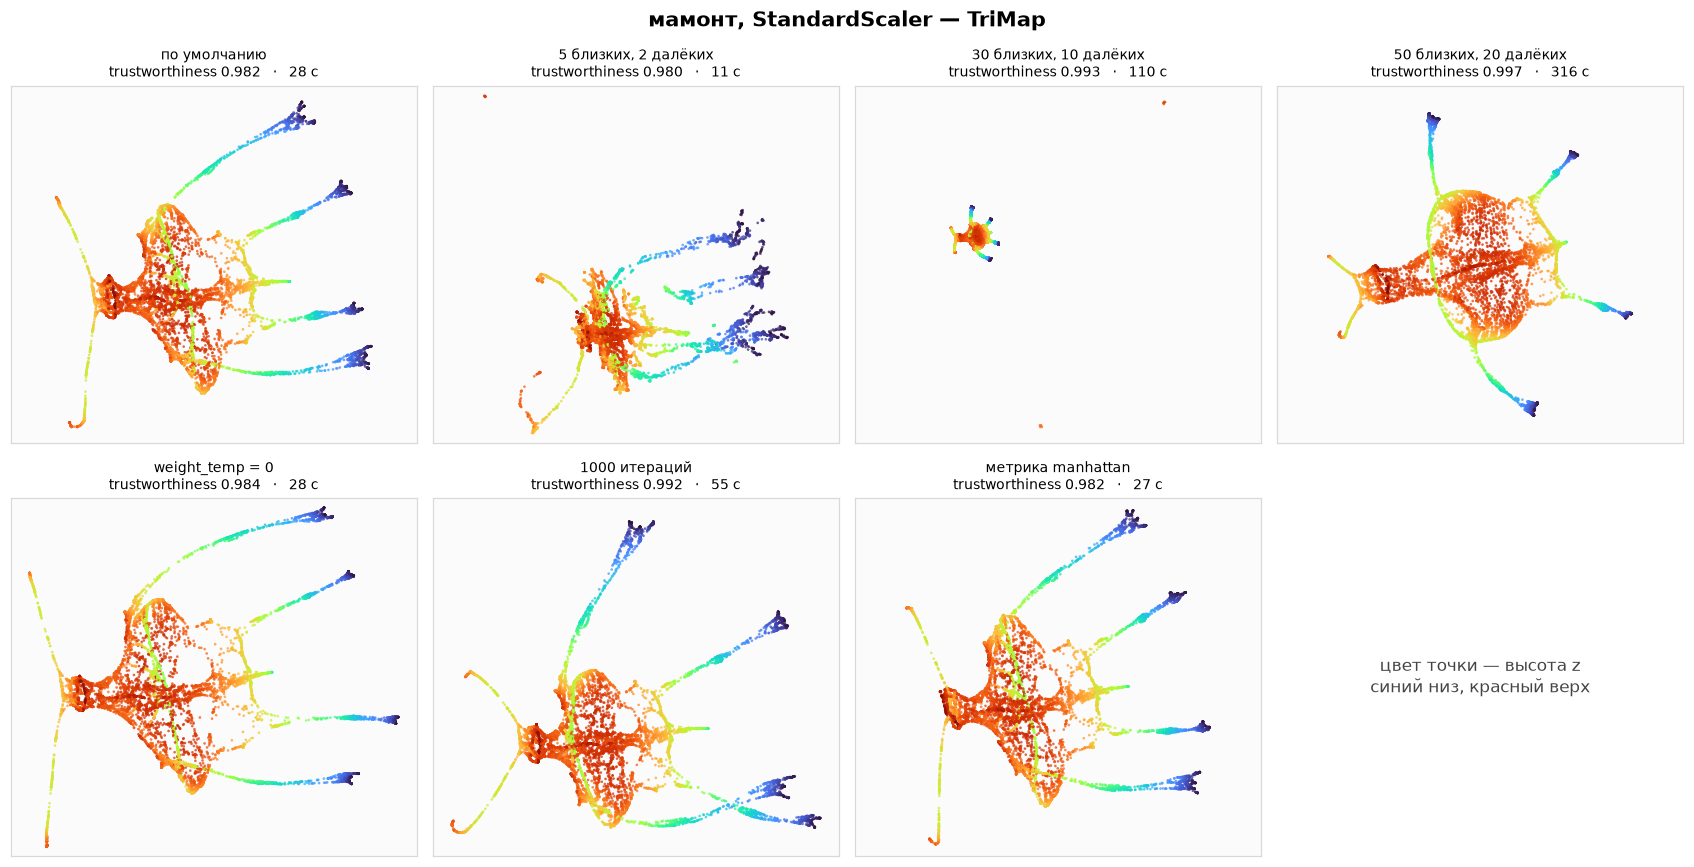

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.9820,27.9
"5 близких, 2 далёких",0.9804,11.1
"30 близких, 10 далёких",0.9926,109.9
"50 близких, 20 далёких",0.9968,315.5
weight_temp = 0,0.9840,28.2
1000 итераций,0.9920,55.0
метрика manhattan,0.9816,27.1


In [26]:
mammoth_trimap = try_params(
    "TriMap", TRIMAP_SETTINGS, X_mammoth_std, height, equal=True,
    title="мамонт, StandardScaler — TriMap",
)
display(mammoth_trimap)


### 3.5 PaCMAP

`MN_ratio` отвечает за то, чтобы голова, корпус и ноги не уехали друг от друга.
`FP_ratio` отвечает за то, чтобы они не слиплись в одно пятно.

PaCMAP  | по умолчанию                 | trustworthiness 0.9928 |  12.5 с
PaCMAP  | 5 соседей                    | trustworthiness 0.9875 |   6.7 с
PaCMAP  | 30 соседей                   | trustworthiness 0.9948 |  34.5 с
PaCMAP  | MN_ratio = 0.1               | trustworthiness 0.9962 |  11.0 с
PaCMAP  | MN_ratio = 2                 | trustworthiness 0.9949 |  18.9 с
PaCMAP  | FP_ratio = 5                 | trustworthiness 0.9983 |  21.5 с
PaCMAP  | метрика manhattan            | trustworthiness 0.9943 |  12.9 с


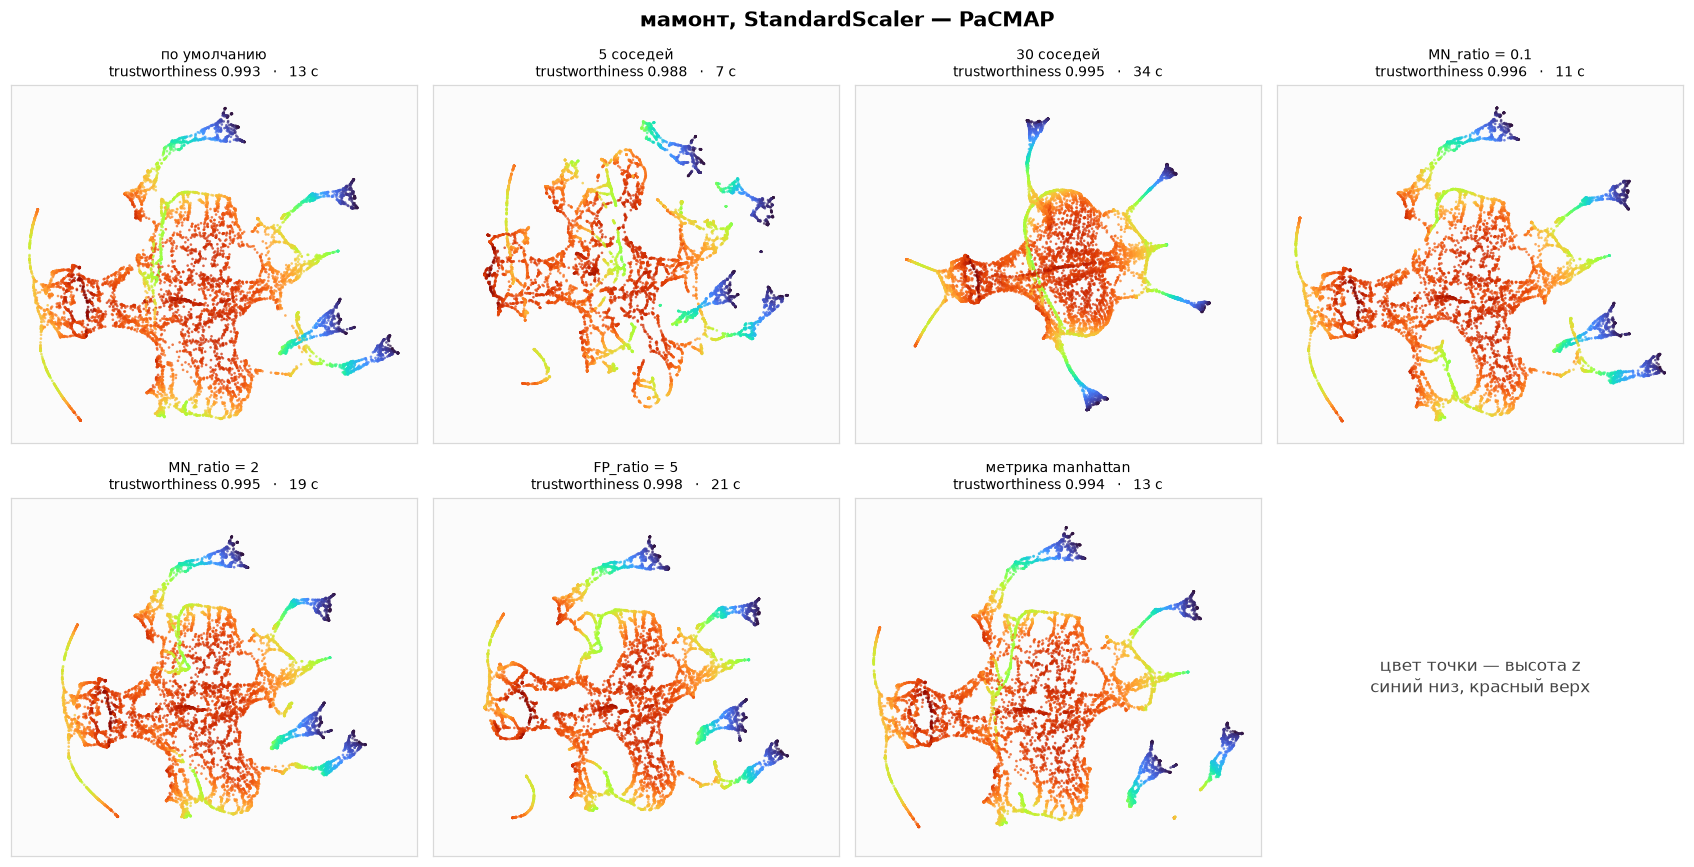

,trustworthiness,"Время, с"
Параметры,,
по умолчанию,0.9928,12.5
5 соседей,0.9875,6.7
30 соседей,0.9948,34.5
MN_ratio = 0.1,0.9962,11.0
MN_ratio = 2,0.9949,18.9
FP_ratio = 5,0.9983,21.5
метрика manhattan,0.9943,12.9


In [27]:
mammoth_pacmap = try_params(
    "PaCMAP", PACMAP_SETTINGS, X_mammoth_std, height, equal=True,
    title="мамонт, StandardScaler — PaCMAP",
)
display(mammoth_pacmap)


### 3.6 Одни и те же алгоритмы на разных масштабах

t-SNE   | без масштабирования    | trustworthiness 0.9987 | 212.8 с
t-SNE   | MinMax                 | trustworthiness 0.9985 | 213.6 с
t-SNE   | Standard               | trustworthiness 0.9986 | 213.1 с
t-SNE   | Robust                 | trustworthiness 0.9985 | 223.5 с
UMAP    | без масштабирования    | trustworthiness 0.9979 |  42.0 с
UMAP    | MinMax                 | trustworthiness 0.9980 |  42.7 с
UMAP    | Standard               | trustworthiness 0.9982 |  41.9 с
UMAP    | Robust                 | trustworthiness 0.9979 |  42.7 с
TriMap  | без масштабирования    | trustworthiness 0.9810 |  27.3 с
TriMap  | MinMax                 | trustworthiness 0.9713 |  27.1 с
TriMap  | Standard               | trustworthiness 0.9851 |  24.8 с
TriMap  | Robust                 | trustworthiness 0.9757 |  28.0 с
PaCMAP  | без масштабирования    | trustworthiness 0.9847 |  13.1 с
PaCMAP  | MinMax                 | trustworthiness 0.9932 |  12.7 с
PaCMAP  | Standard               | trustworthine

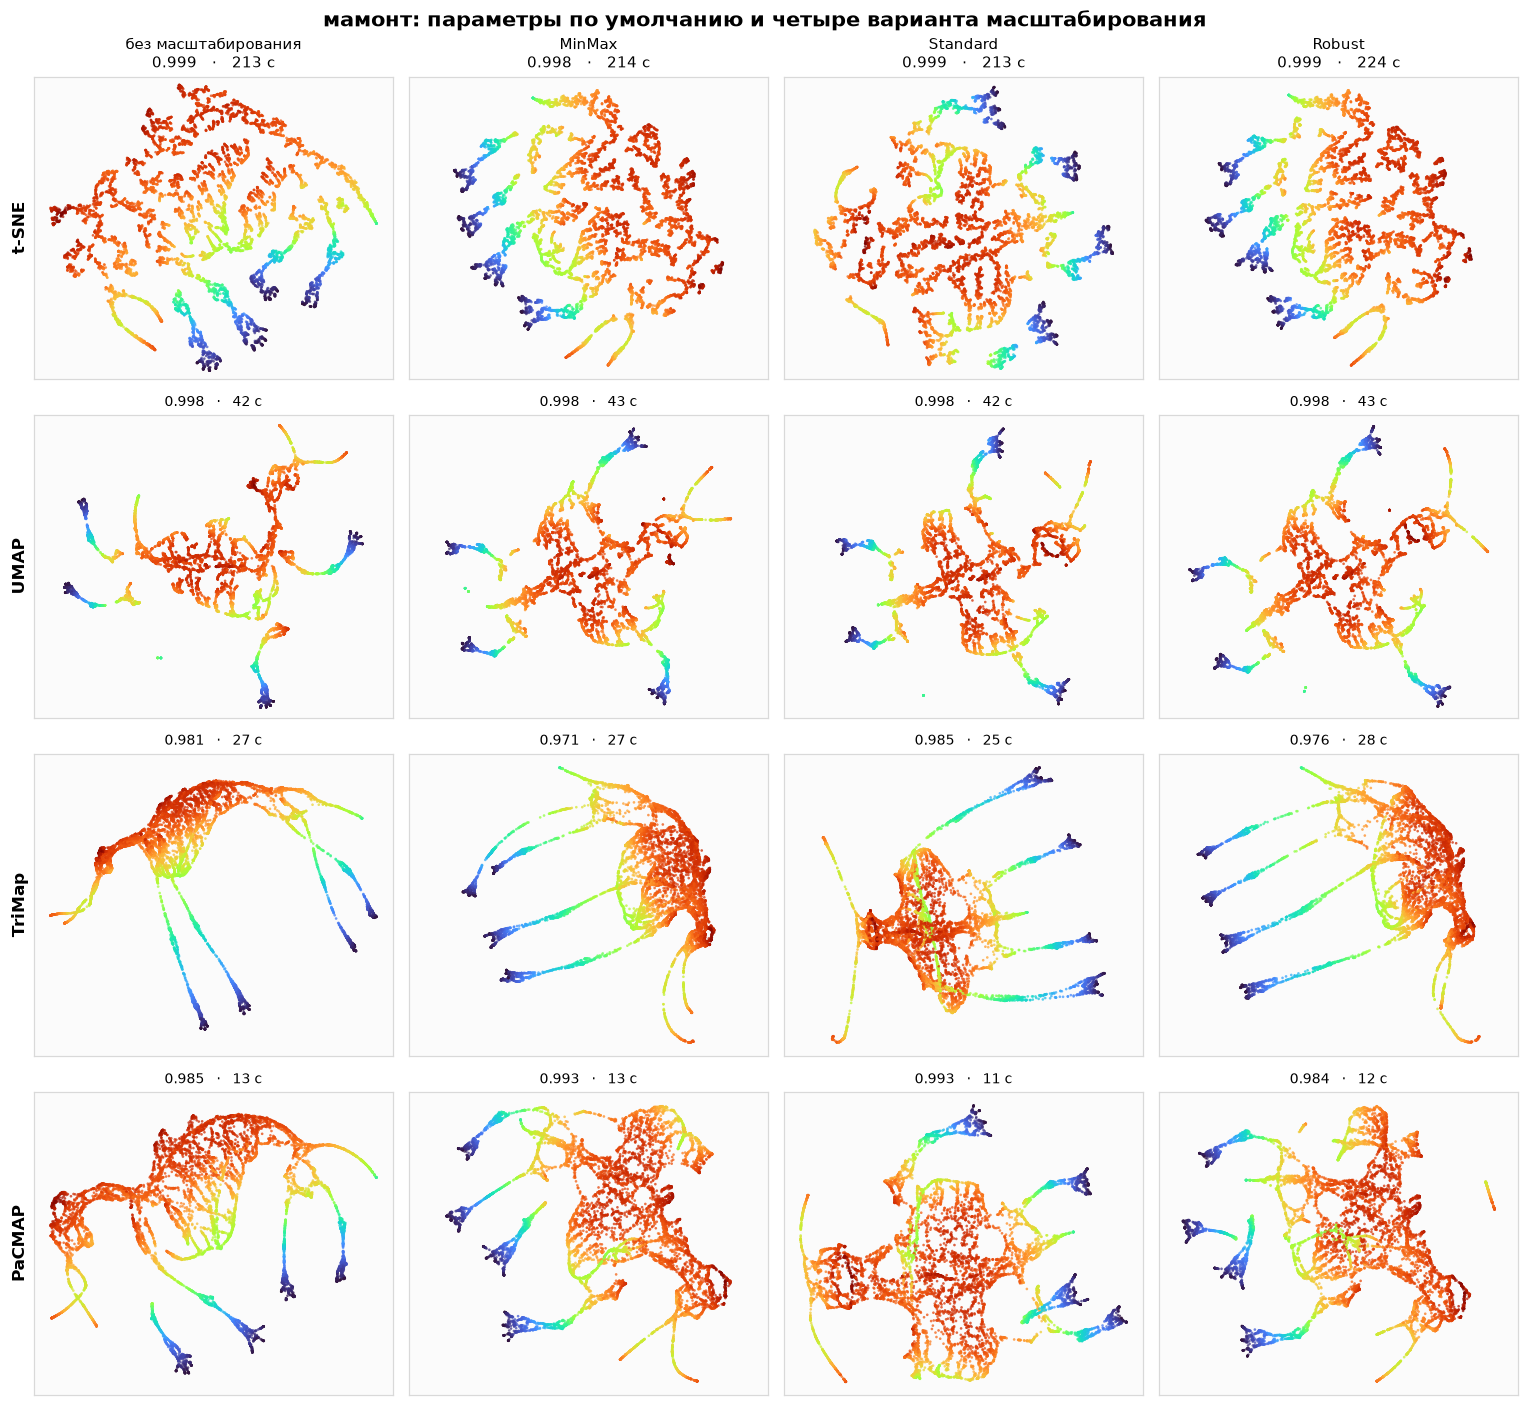

trustworthiness


Масштабирование,без масштабирования,MinMax,Standard,Robust
Алгоритм,,,,
t-SNE,0.9987,0.9985,0.9986,0.9985
UMAP,0.9979,0.9980,0.9982,0.9979
TriMap,0.9810,0.9713,0.9851,0.9757
PaCMAP,0.9847,0.9932,0.9928,0.9840


In [28]:
mammoth_scaling = try_scaling(
    mammoth, height, equal=True,
    title="мамонт: параметры по умолчанию и четыре варианта масштабирования",
)
print("trustworthiness")
display(mammoth_scaling)


### 3.7 Сравнение алгоритмов на мамонте

Рядом ещё раз показаны вложения с параметрами по умолчанию: так проще сравнить форму, а не только число.

In [29]:
mammoth_results = []
for method, result in [("t-SNE", mammoth_tsne), ("UMAP", mammoth_umap),
                       ("TriMap", mammoth_trimap), ("PaCMAP", mammoth_pacmap)]:
    part = result.reset_index()
    part.insert(0, "Алгоритм", method)
    mammoth_results.append(part)
mammoth_results = pd.concat(mammoth_results, ignore_index=True)

print("Среднее и лучшее значение по 7 настройкам")
display(
    mammoth_results.groupby("Алгоритм")[["trustworthiness", "Время, с"]]
    .agg(["mean", "max"])
    .round(4)
    .loc[METHODS]
)

best_rows = mammoth_results.groupby("Алгоритм")["trustworthiness"].idxmax()
print("Лучшая настройка каждого алгоритма")
display(mammoth_results.loc[best_rows].set_index("Алгоритм").loc[METHODS])


Среднее и лучшее значение по 7 настройкам


trustworthiness          Время, с       
                    mean     max      mean    max
Алгоритм                                         
t-SNE             0.9946  0.9989  229.2143  302.9
UMAP              0.9866  0.9984   69.6143  119.0
TriMap            0.9871  0.9968   82.1000  315.5
PaCMAP            0.9941  0.9983   16.8571   34.5

Лучшая настройка каждого алгоритма


,Параметры,trustworthiness,"Время, с"
Алгоритм,,,
t-SNE,perplexity = 100,0.9989,302.9
UMAP,"200 соседей, min_dist = 0.5",0.9984,119.0
TriMap,"50 близких, 20 далёких",0.9968,315.5
PaCMAP,FP_ratio = 5,0.9983,21.5


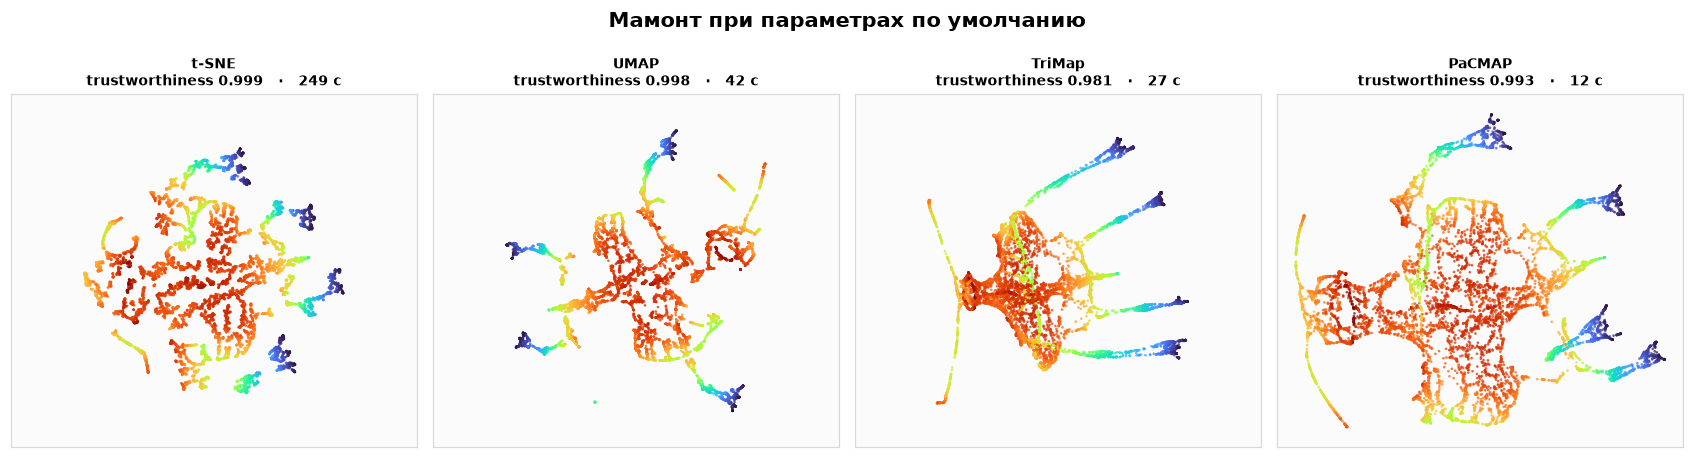

In [30]:
# Повторный прогон с пустыми параметрами: четыре алгоритма рядом, чтобы сравнить форму силуэта.
figure, axes = plt.subplots(1, 4, figsize=(15.5, 4.2))
for ax, method in zip(axes, METHODS):
    Y, seconds = embed(method, X_mammoth_std)
    draw(ax, Y, height, equal=True)
    quality = neighborhood_score(X_mammoth_std, Y)
    ax.set_title(f"{method}\ntrustworthiness {quality:.3f}   ·   {seconds:.0f} с", fontweight="bold")
figure.suptitle("Мамонт при параметрах по умолчанию", fontsize=14, fontweight="bold")
figure.tight_layout()
plt.show()


## 4. Общий итог

In [31]:
# Одна таблица по двум заданиям: качество вложения и время.
totals = pd.DataFrame({
    "scene, средний trustworthiness": scene_results.groupby("Алгоритм")["trustworthiness"].mean(),
    "scene, лучший trustworthiness": scene_results.groupby("Алгоритм")["trustworthiness"].max(),
    "scene, среднее время, с": scene_results.groupby("Алгоритм")["Время, с"].mean(),
    "мамонт, средний trustworthiness": mammoth_results.groupby("Алгоритм")["trustworthiness"].mean(),
    "мамонт, лучший trustworthiness": mammoth_results.groupby("Алгоритм")["trustworthiness"].max(),
    "мамонт, среднее время, с": mammoth_results.groupby("Алгоритм")["Время, с"].mean(),
}).loc[METHODS].round(3)
display(totals)


,"scene, средний trustworthiness","scene, лучший trustworthiness","scene, среднее время, с","мамонт, средний trustworthiness","мамонт, лучший trustworthiness","мамонт, среднее время, с"
Алгоритм,,,,,,
t-SNE,0.857,0.864,10.371,0.995,0.999,229.214
UMAP,0.797,0.831,16.443,0.987,0.998,69.614
TriMap,0.820,0.835,11.257,0.987,0.997,82.100
PaCMAP,0.817,0.859,2.000,0.994,0.998,16.857
